# embher on simulated donors

A self-contained example of the two parts of embher.

1. Simulate donors and a phenotype with a known heritability.
2. Get one embedding per donor, either simulated or from Borzoi (see `SIMULATED_EMBEDDING`).
3. Estimate genotype heritability with exact AI-REML (`embher.heritability.fit_reml`) and Haseman-Elston regression (`he_fit`).
4. Whiten the embedding (`embher.embedding.whiten`), use it as a kernel, and compare with a donor-shuffled null.

With `SIMULATED_EMBEDDING = True` nothing beyond the base install is needed (`pip install embher`): no weights, no GPU, no external files. With `False` the embeddings come from Borzoi and the notebook needs `embher[capture-borzoi]`, a GPU, the hg38 FASTA and the Borzoi weights.

![embher schematic](../docs/schematic.png)

*Regenerate the figure with `python docs/make_schematic.py`.*

In [1]:
# On a shared node, set OMP_NUM_THREADS to the CPUs you were allocated before starting Python:
# numpy otherwise starts one BLAS thread per core of the node, which crawls on a 1-CPU job.
import numpy as np
import matplotlib.pyplot as plt

from embher.heritability import build_grm, fit_reml, he_fit
from embher.embedding import whiten

SIMULATED_EMBEDDING = True   # True: simulated embedding, runs anywhere. False: embed with Borzoi (GPU).

# Only used when SIMULATED_EMBEDDING = False
HG38_FASTA = "/path/to/GRCh38.primary_assembly.genome.fa.gz"   # bgzipped, with .fai and .gzi
BORZOI_WEIGHTS = None            # local folder with the weights, or None to download johahi/borzoi-replicate-0
GENE_CHROM, GENE_TSS = "chr5", 180_988_845                   # BTNL3: the window is centred on the TSS
N_DONORS_BORZOI = 300            # two forward passes per donor
N_VARIANTS_BORZOI = 200          # random SNVs within +-75 kb of the TSS

rng = np.random.default_rng(0)
h2_true = 0.5

## 1. Donors

Dosages (0/1/2) with random allele frequencies. In Borzoi mode the two haplotypes of each donor are simulated separately, as random SNVs on the reference window around the TSS, because the model reads sequences.

In [2]:
if SIMULATED_EMBEDDING:
    n, m = 1000, 3000
    maf = rng.uniform(0.05, 0.5, m)
    dosage = rng.binomial(2, maf, size=(n, m)).astype(float)
else:
    n, m = N_DONORS_BORZOI, N_VARIANTS_BORZOI
    maf = rng.uniform(0.05, 0.5, m)
    hap = rng.random((n, 2, m)) < maf                  # allele carried by each haplotype
    dosage = hap.sum(axis=1).astype(float)

X = np.column_stack([np.ones(n), rng.normal(size=n)])  # intercept + one covariate
K, n_used = build_grm(dosage)
print(f"{n} donors, GRM {K.shape}, {n_used} variants")

1000 donors, GRM (1000, 1000), 3000 variants


## 2. Embedding and phenotype

**Simulated:** the phenotype is a genetic value (standardised genotypes times small random effects) plus noise, with a genetic share `h2_true`. The embedding has 200 features that mix that genetic value with donor-specific structure unrelated to the phenotype.

**Borzoi:** each haplotype's window (524 kb centred on the TSS, reference with the donor's SNVs applied) goes through Borzoi once. The embedding is the final embedding mean-pooled over the sequence, averaged over the donor's two haplotypes. The phenotype is Borzoi's own predicted coverage (mean over the central 4 kb and all tracks), rescaled to a genetic share of `h2_true` plus noise. The model is the ground truth here, so the question is how much of it the genotype kernel and the embedding kernel each capture.

In [3]:
if SIMULATED_EMBEDDING:
    z = (dosage - 2 * maf) / np.sqrt(2 * maf * (1 - maf))           # standardised genotypes
    g = z @ rng.normal(0, np.sqrt(h2_true / m), m)                  # genetic value, var ~ h2_true
    y = g + rng.normal(0, np.sqrt(1 - h2_true), n)                  # phenotype, var ~ 1

    n_feat = 200
    loading = rng.normal(size=n_feat)
    latent = rng.normal(size=(n, 10)) @ rng.normal(size=(10, n_feat))   # unrelated structure
    Z = 1.5 * np.outer(g / g.std(), loading) + latent + rng.normal(size=(n, n_feat))
else:
    import pysam
    from tqdm.auto import tqdm
    from embher.embedding.utils import init_borzoi_model, BORZOI_SEQ_LEN
    from embher.embedding.capture import borzoi
    from embher.embedding.capture.reduce import Pooling

    model, _ = init_borzoi_model(model_name=BORZOI_WEIGHTS)
    win_start = GENE_TSS - BORZOI_SEQ_LEN // 2
    with pysam.FastaFile(HG38_FASTA) as fasta:
        ref = list(fasta.fetch(GENE_CHROM, win_start, win_start + BORZOI_SEQ_LEN).upper())
    pos = np.sort(rng.choice(np.arange(-75_000, 75_000), m, replace=False)) + BORZOI_SEQ_LEN // 2
    alt = [rng.choice([b for b in "ACGT" if b != ref[p]]) for p in pos]

    def embed_and_predict(alleles):
        seq = ref.copy()
        for p, a, carried in zip(pos, alt, alleles):
            if carried:
                seq[p] = a
        out = borzoi.run_forward(
            model, "".join(seq), BORZOI_SEQ_LEN, win_start,
            crop_start=GENE_TSS - 2048, crop_end=GENE_TSS + 2048,
            embedding_crop=False, poolings=[Pooling("seq_dim", "mean")],
            embedding_layers=borzoi.FINAL_EMBEDDINGS)
        return out["embeddings/final__seq_mean"][0], out["predictions/human"][0].mean()

    runs = [[embed_and_predict(hap[i, h]) for h in (0, 1)] for i in tqdm(range(n))]
    Z = np.array([np.mean([e for e, _ in r], axis=0) for r in runs], dtype=np.float64)
    pred = np.array([np.mean([p for _, p in r]) for r in runs])
    pred = (pred - pred.mean()) / pred.std()
    y = np.sqrt(h2_true) * pred + rng.normal(0, np.sqrt(1 - h2_true), n)

print("embedding", Z.shape, "phenotype", y.shape)

embedding (1000, 200) phenotype (1000,)


## 3. Heritability from the genotype GRM

`fit_reml` and `he_fit` take a list of kernels, the phenotype and a design matrix that already contains the intercept.

In [4]:
reml = fit_reml([K], y, X)
print(f"REML  h2 = {reml['h2']:.3f} +/- {reml['h2_se']:.3f}   (target {h2_true})")

he = he_fit([K], y[:, None], X, jackknife=False)
theta, a = he["theta"][:, 0], he["a"]
h2_he = a[0] * theta[0] / (a * theta).sum()
print(f"HE    h2 = {h2_he:.3f}")

REML  h2 = 0.400 +/- 0.078   (target 0.5)
HE    h2 = 0.384


## 4. The embedding as a kernel

`whiten_embeddings` standardises the features and returns the top-k PC scores with unit variance; their GRM is the embedding kernel. Shuffling the donors of the embedding breaks its link to the phenotype and gives the null.

In [5]:
def embedding_h2(Z, y, n_pcs=10):
    S = whiten.whiten_embeddings(Z, n_pcs=n_pcs, verbose=False)
    K_emb = S @ S.T / S.shape[1]
    return fit_reml([K_emb], y, X)

emb = embedding_h2(Z, y)
null = [embedding_h2(Z[rng.permutation(n)], y)["h2"] for _ in range(10)]
print(f"embedding h2 = {emb['h2']:.3f} +/- {emb['h2_se']:.3f}")
print(f"shuffled donors: mean {np.mean(null):.3f}, max {np.max(null):.3f}  (10 shuffles)")

embedding h2 = 0.468 +/- 0.113
shuffled donors: mean -0.001, max 0.007  (10 shuffles)


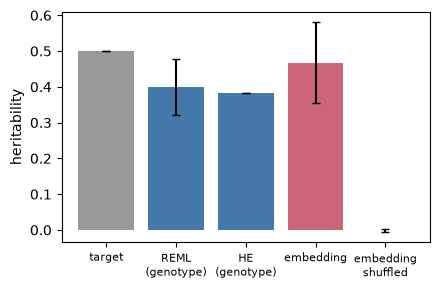

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 3))
labels = ["target", "REML\n(genotype)", "HE\n(genotype)", "embedding", "embedding\nshuffled"]
vals = [h2_true, reml["h2"], h2_he, emb["h2"], np.mean(null)]
errs = [0, reml["h2_se"], 0, emb["h2_se"], np.std(null)]
ax.bar(labels, vals, yerr=errs, color=["#999", "#4477aa", "#4477aa", "#cc6677", "#ddd"], capsize=3)
ax.set_ylabel("heritability")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()

**Simulated:** the genotype estimates recover the simulated value. The genetic value is a strong direction in the embedding, so its whitened top PCs carry it and the embedding kernel recovers about the same heritability; shuffling donors removes it. With a weaker genetic signal the embedding estimate drops towards 0, since whitening gives every retained PC equal weight.

**Borzoi:** read the bars the same way, but note the phenotype is a nonlinear function of the sequence, so the linear genotype kernel need not recover the target, while the embedding sits one step before the model's output.

Next: `embher.heritability.bin_masks` for MAF/LD-binned multi-kernel fits, `fit_reml(..., nonneg=True)` for the constrained fit with its LRT, and `embher-capture` for real cohorts (VCF, genes, HDF5 output).